E-commerce is a huge business sector that allows customers to access a variety of goods and services with a few clicks. Many popular shopping platforms such as Amazon or Alibaba process millions of transactions annually. In recent years, due to the corona disease, online shopping has increased dramatically, therefore, the online shopping market has become very competitive and it is important for strong and innovative online shopping platforms.   
One possible way to increase online shopping transactions is to understand and respond to customers' behavior. According to sufficient online shopping data and machine learning techniques, it is possible to determine the purchase intention of website visitors, so in this exercise, we want to use machine learning algorithms in Marketing Analytics, which is one of the topics discussed in recent years. let's get to know each other more.

## Dataset

Before doing anything, we need to get familiar with Dataset. The desired dataset is located in the `customers_intention.csv` file. This dataset contains various information related to customer behavior on online shopping websites, which helps us to perform marketing analysis and understand related KPIs and metrics. This dataset contains feature vectors belonging to 12330 sessions, in the sense that each row shows the behavior of a customer to buy a product and has a total of 10 numerical features and 8 categorical features. 
Use the "Revenue" property as the class label.

in this section, what you have to do is as follows:
 - lead the dataset
 - print information of the dataset
 - plot number of data for each label in `Revenue` column.

In [1]:
# 40023055 ArianAbdollahi
# Load dataset
import pandas as pd

df = pd.read_csv("C:\\Users\\Arian\\Desktop\\DM_P3\\Customers_intention.csv") #load data
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


In [2]:
# dataset information
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

<Axes: xlabel='Revenue'>

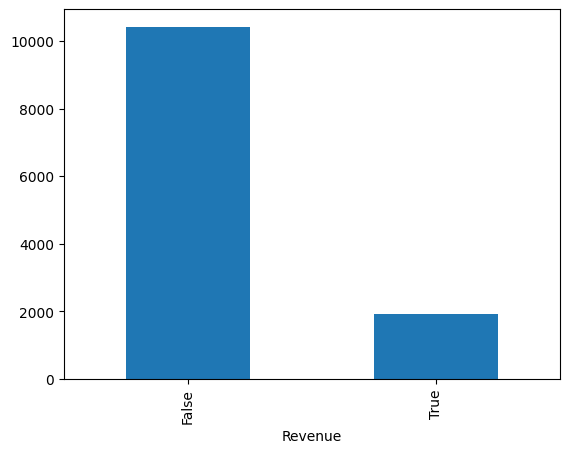

In [3]:
# plot number of data for each class label
df["Revenue"].value_counts().plot(kind='bar')


## Data Cleaning

Now, after reading the data, it is time to clean the data. At this stage, we need to do the necessary pre-processing to clean the dataset. Some of the things we suggest you do are as follows:
- Identification of null values
- Handling the null values of each column in an appropriate way
- one-hot encoding of categorical columns. you can use this [link](https://machinelearningmastery.com/why-one-hot-encode-data-in-machine-learning/) for one-hot encoding
And any pre-processing you want.

In [4]:
# identify and handle nan values
print(df.isnull().sum().sum())
# drop columns that have correlation with another column
df = df.drop(["Administrative","Informational","ProductRelated"], axis = 1)


0


In [5]:
import numpy as np 
from scipy.stats import boxcox

columns = ["Administrative_Duration","Informational_Duration","ProductRelated_Duration","PageValues"]

# using boxcox to normal high range data
for i in columns:
    print(df[i].skew())
    df[i] = df[i] + 1
    df[i] , _ = boxcox(df[i])
    print(df[i].skew())
df    

5.61571901877419
0.14548486105413014
7.579184715734214
1.5469030402129191
7.263227682561318
-0.03633623414663036
6.382964248998133
1.3774203430455354


,Administrative_Duration,Informational_Duration,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0.000000,0.0,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0.000000,0.0,6.990788,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0.000000,0.0,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0.000000,0.0,1.513204,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0.000000,0.0,14.727490,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3.879037,0.0,19.881739,0.007143,0.029031,0.673415,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0.000000,0.0,13.470013,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0.000000,0.0,10.068619,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,3.478846,0.0,12.299439,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


In [6]:
#Initialize the LabelEncoder
from sklearn.preprocessing import LabelEncoder
# using labelencoder instead of one hot encoder  
label_encoder = LabelEncoder()

# Identify categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns

# Apply LabelEncoder to each categorical column and remove original columns
for col in categorical_columns:
    df[col + '_Encoded'] = label_encoder.fit_transform(df[col])
    df.drop(columns=[col], inplace=True)



## Train/Test Split
- Divide the data into two parts, train and test. Assign `80%` of the data to the train section.
    - split in a `stratified` fashion. (Hint: you need to change a parameter in the corresponding method)

In [7]:
# import train test split from sklearn
from sklearn.model_selection import train_test_split

In [8]:
# train test split
X = df.loc[:,(df.columns != "Revenue")]  
Y = df.loc[:,"Revenue"]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.20, stratify = Y,random_state = 1)
X

,Administrative_Duration,Informational_Duration,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Month_Encoded,VisitorType_Encoded
0,0.000000,0.0,0.000000,0.200000,0.200000,0.000000,0.0,1,1,1,1,False,2,2
1,0.000000,0.0,6.990788,0.000000,0.100000,0.000000,0.0,2,2,1,2,False,2,2
2,0.000000,0.0,0.000000,0.200000,0.200000,0.000000,0.0,4,1,9,3,False,2,2
3,0.000000,0.0,1.513204,0.050000,0.140000,0.000000,0.0,3,2,2,4,False,2,2
4,0.000000,0.0,14.727490,0.020000,0.050000,0.000000,0.0,3,3,1,4,True,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3.879037,0.0,19.881739,0.007143,0.029031,0.673415,0.0,4,6,1,1,True,1,2
12326,0.000000,0.0,13.470013,0.000000,0.021333,0.000000,0.0,3,2,1,8,True,7,2
12327,0.000000,0.0,10.068619,0.083333,0.086667,0.000000,0.0,3,2,1,13,True,7,2
12328,3.478846,0.0,12.299439,0.000000,0.021053,0.000000,0.0,2,2,3,11,False,7,2


## Classification Using Regression

- Assign +1 to every instance of customer visit that led to a purchase and assign -1 to every visit that did not lead to a purchase.
- Using a regression model (univariate, multivariate, linear, polynomial, etc.), predict whether a cutomer's visit will lead to a purchase or not.
- How do you decide whether a visit will lead to a purchase based on the output of the model which is a real-valued number? 

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

scaler = StandardScaler()

Y_train_C = Y_train.apply(lambda x: 1 if x else -1)
Y_test_C = Y_test.apply(lambda x: 1 if x else -1)
X_train_C = scaler.fit_transform(X_train)
X_test_C = scaler.transform(X_test)

regressor = LinearRegression()
regressor.fit(X_train_C, Y_train_C)

print("intercept :",regressor.intercept_)
print("\ncoefficients of regression model :",regressor.coef_)
y_pred_train = regressor.predict(X_train_C)

# Predicting the Test set results
y_pred = regressor.predict(X_test_C)

print("\ny_pred :",y_pred)

for i in range(len(y_pred)) :
    y_pred[i] = 1 if (y_pred[i] > 0) else -1
print("\ny_pred after convert to 1,-1 :",y_pred)
  
print("\nmse is :",mean_squared_error(Y_test_C, y_pred))
from sklearn.metrics import classification_report
print(classification_report(Y_test_C, y_pred))


intercept : -0.6905920519059204

coefficients of regression model : [-0.0530141  -0.0072263  -0.00386575  0.03562653 -0.07851738  0.44302754
 -0.03376542 -0.00791646  0.0104677  -0.00932534  0.01198507  0.00834855
  0.0369671  -0.06436309]

y_pred : [-0.93773043 -1.14171712 -1.10409998 ... -0.94215874 -0.96372436
  0.42486284]

y_pred after convert to 1,-1 : [-1. -1. -1. ... -1. -1.  1.]

mse is : 0.4606650446066504
              precision    recall  f1-score   support

          -1       0.95      0.91      0.93      2084
           1       0.61      0.74      0.67       382

    accuracy                           0.88      2466
   macro avg       0.78      0.82      0.80      2466
weighted avg       0.90      0.88      0.89      2466



## Dimensionality Reduction
Dimensionality reduction, or dimension reduction, is the transformation of data from a high-dimensional space into a low-dimensional space so that the low-dimensional representation retains some meaningful properties of the original data, ideally close to its intrinsic dimension. Working in high-dimensional spaces can be undesirable for many reasons; raw data are often sparse as a consequence of the curse of dimensionality, and analyzing the data is usually computationally intractable (hard to control or deal with).


in this section you ar goinig to:
- plot datapoints in 2 dimensions using PCA
- Choose the best number of dimensions for PCA by plotting [cumulative explained variance ratio](https://medium.com/@megha.natarajan/understanding-cumulative-explained-variance-in-pca-with-python-653e3592a77c#:~:text=The%20Cumulative%20Explained%20Variance%20plot%20is%20a%20graphical%20representation%20that,the%20variance%20in%20the%20data.)
- Apply pca to the dataset with the number of dimensions you obtained in the previous section

*`don't remember you to standardize data before PCA transformation!`*

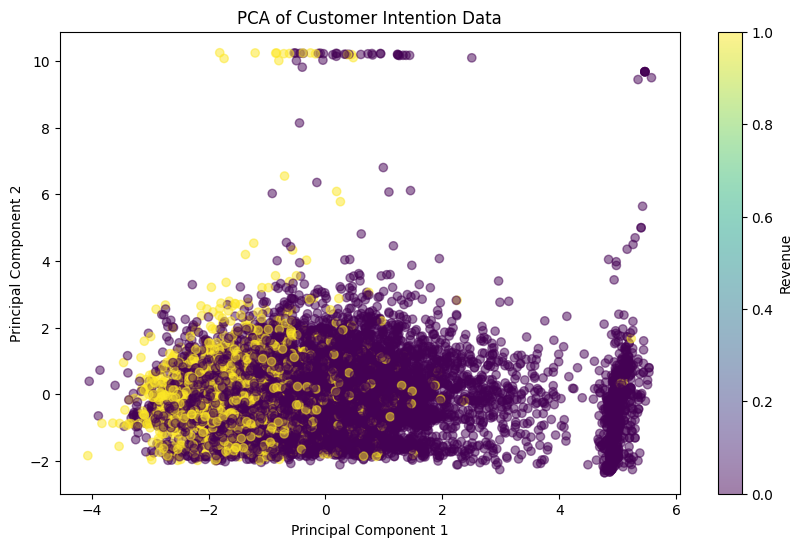

In [10]:
# plot datapoints in 2 dimensions using PCA

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_S = scaler.fit_transform(X)


# Apply PCA to reduce to 2 dimensions
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_S)

# Create a DataFrame with the principal components
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])

# Plot the 2D projection
plt.figure(figsize=(10, 6))
plt.scatter(pca_df['PC1'], pca_df['PC2'], alpha=0.5, c=df['Revenue'].apply(lambda x: 1 if x else 0))
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Customer Intention Data')
plt.colorbar(label='Revenue')
plt.show()

[0.21697278 0.09999301 0.08904997 0.07926888 0.07503203 0.06841628
 0.06777948 0.06153196 0.06082911 0.05492197 0.05284506 0.04126429
 0.02704389 0.00505129]


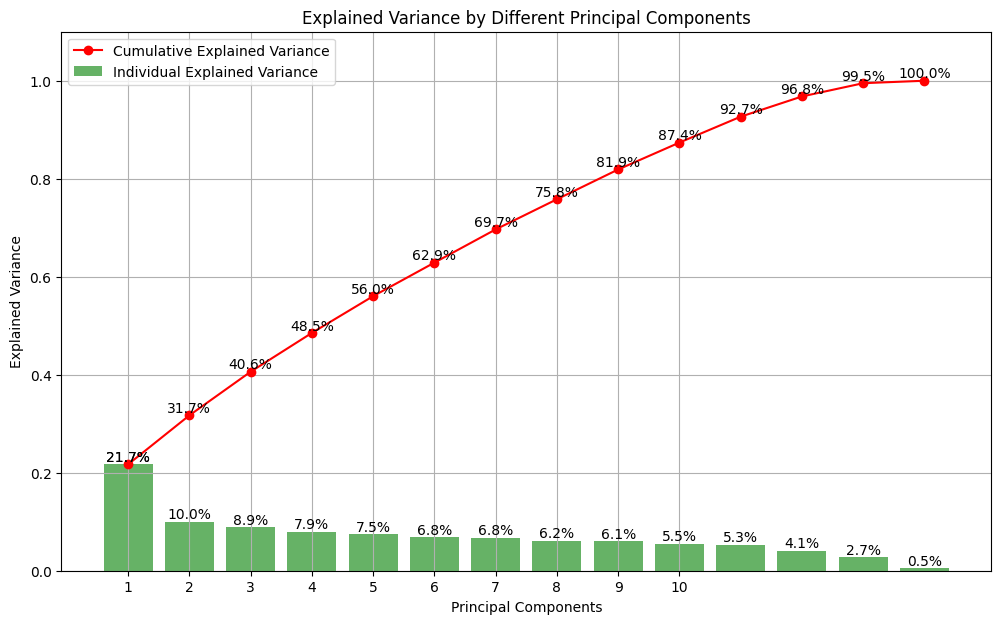

In [11]:
import numpy as np

# Choose the best number of dimensions for PCA
pca = PCA(n_components=14)
pca.fit(X_S)

individual_variances = pca.explained_variance_ratio_
print(individual_variances)
# Calculate the cumulative explained variance ratio
cumulative_variances = np.cumsum(individual_variances)

# Create the bar plot for individual variances
plt.figure(figsize=(12, 7))
bar = plt.bar(range(1, 15), individual_variances, alpha=0.6, color='g', label='Individual Explained Variance')

# Create the line plot for cumulative variance
line = plt.plot(range(1, 15), cumulative_variances, marker='o', linestyle='-', color='r', 
                label='Cumulative Explained Variance')

# Adding percentage values on top of bars and dots
for i, (bar, cum_val) in enumerate(zip(bar, cumulative_variances)):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{individual_variances[i]*100:.1f}%', 
             ha='center', va='bottom')
    plt.text(i+1, cum_val, f'{cum_val*100:.1f}%', ha='center', va='bottom')

# Aesthetics for the plot
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title('Explained Variance by Different Principal Components')
plt.xticks(range(1, 11))
plt.legend(loc='upper left')
plt.ylim(0, 1.1)  # extend y-axis limit to accommodate text labels
plt.grid(True)
plt.show()

In [12]:
# Apply pca
sc = StandardScaler()

X_train_C = sc.fit_transform(X_train)
X_test_C = sc.transform(X_test)

pca = PCA(n_components = 6)

X_train_P = pca.fit_transform(X_train_C)
X_test_P = pca.transform(X_test_C)

from sklearn.linear_model import LogisticRegression  

classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train_P, Y_train_C)
y_pred = classifier.predict(X_test_P)

print("\ny_pred :",list(y_pred))
print("\nY_test_C :",list(Y_test_C)) 
print("\nmse is :",mean_squared_error(Y_test_C, y_pred))


from sklearn.metrics import classification_report
print(classification_report(Y_test_C, y_pred))




y_pred : [-1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, 1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, -1, -1, -1, -1, -1, -1, -1, 1

## Over-Sampling

Imbalanced classification involves developing predictive models on classification datasets that have a severe class imbalance.

The challenge of working with imbalanced datasets is that most machine learning techniques will ignore, and in turn have poor performance on, the minority class, although typically it is performance on the minority class that is most important.

One approach to addressing imbalanced datasets is to oversample the minority class. The simplest approach involves duplicating examples in the minority class, although these examples don’t add any new information to the model. Instead, new examples can be synthesized from the existing examples. This is a type of data augmentation for the minority class and is referred to as the Synthetic Minority Oversampling Technique, or SMOTE for short.

in this section you are going to use `SMOTE` method for over-sampling data to get equal number of data for each data. After applying SMOTE plot number of data for each class again to see the diffrence.
- [over-smapling](https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/)

In [13]:
# import  imblearn library for SMOTE
from imblearn.over_sampling import SMOTE 

In [14]:
# Apply SMOTE
sm = SMOTE(random_state = 2) 
X_train_res, y_train_res = sm.fit_resample(X_train_P, Y_train_C) 

After OverSampling, the shape of train_X: (16676, 6)
After OverSampling, the shape of train_y: (16676,) 

After OverSampling, counts of label '1': 8338
After OverSampling, counts of label '-1': 8338


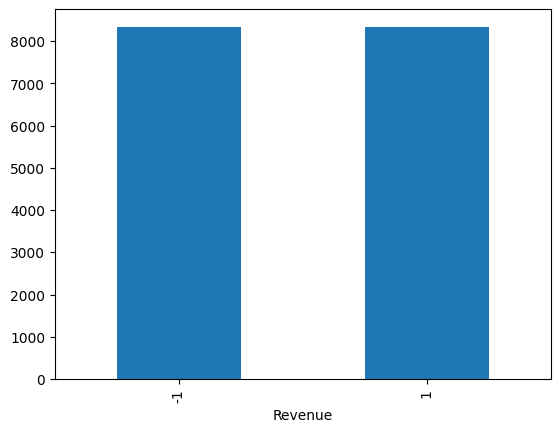

In [15]:
# plot number of data for each class
y_train_res.value_counts().plot(kind='bar')

print('After OverSampling, the shape of train_X: {}'.format(X_train_res.shape)) 
print('After OverSampling, the shape of train_y: {} \n'.format(y_train_res.shape)) 

print("After OverSampling, counts of label '1': {}".format(sum(y_train_res == 1))) 
print("After OverSampling, counts of label '-1': {}".format(sum(y_train_res == -1))) 


## Training Classifiers

Classification is the process of predicting the class of given data points. Classes are sometimes called as targets/ labels or categories. Classification predictive modeling is the task of approximating a mapping function (f) from input variables (X) to discrete output variables (y).

in this section you are going to train several cllassifiers like:
- `SVM`
- `KNN`
- `Logistic Regression`
- `Decision Tree`

Use the dimensionally reduced `train` data to train the specified classifiers. 
- for each classifier use `gridsearch` to find best hyper parameters.
    - use `cross validation` for grid search
- after finding best parameters for each classifier, use them to train a classifier with founded parameters.
    - again train your best classifiers with `cross valdiation`
- use a bar plot to show each classifier's `accuracy`, `precision`, `f1` and `roc_auc`.

In [16]:
# Import Necessary libraries
from sklearn.model_selection import  GridSearchCV
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [17]:
SVM = SVC()

# Define the parameter grid
param_grid = {
    'C': [0.1 , 1 ,10],
    'kernel': ['linear','rbf'],
    'gamma': [0.1, 0.01, 0.001]
}

# Perform grid search
grid_search_svm = GridSearchCV(estimator=SVM, param_grid=param_grid, refit=True, verbose=2, cv=5)
grid_search_svm.fit(X_train_res, y_train_res)
print("Best parameters found: ", grid_search_svm.best_params_)
print("Best accuracy: ", grid_search_svm.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
[CV] END ....................C=0.1, gamma=0.1, kernel=linear; total time=   9.9s
[CV] END ....................C=0.1, gamma=0.1, kernel=linear; total time=   8.2s
[CV] END ....................C=0.1, gamma=0.1, kernel=linear; total time=  11.6s
[CV] END ....................C=0.1, gamma=0.1, kernel=linear; total time=   9.9s
[CV] END ....................C=0.1, gamma=0.1, kernel=linear; total time=   9.6s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=  16.1s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=  16.9s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=  17.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=  16.8s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=  17.0s
[CV] END ...................C=0.1, gamma=0.01, kernel=linear; total time=  10.1s
[CV] END ...................C=0.1, gamma=0.01, k

In [ ]:
knn = KNeighborsClassifier()

# Define the parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9 , 11],
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Perform grid search
grid_search_knn = GridSearchCV(estimator=knn, param_grid=param_grid , refit=True, verbose=2, cv=5)
grid_search_knn.fit(X_train_res, y_train_res)


In [21]:
print("Best parameters found: ", grid_search_knn.best_params_)
print("Best accuracy: ", grid_search_knn.best_score_)

Best parameters found:  {'algorithm': 'auto', 'metric': 'euclidean', 'n_neighbors': 3}
Best accuracy:  0.893439790895919


In [ ]:
logreg = LogisticRegression(max_iter=10000)

# Define the parameter grid
param_grid = {
    'penalty': ['l1', 'l2', 'elasticnet', None],
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag'],
    'l1_ratio': [0, 0.25, 0.5, 0.75, 1],  # Only used if penalty is 'elasticnet'
    'multi_class': ['auto', 'ovr', 'multinomial']
}

# Perform grid search
grid_search_lr = GridSearchCV(estimator=logreg, param_grid=param_grid, refit=True, verbose=2, cv=5)
grid_search_lr.fit(X_train_res, y_train_res)



In [20]:
# Print the best parameters and the best score
print("Best parameters found: ", grid_search_lr.best_params_)
print("Best accuracy: ", grid_search_lr.best_score_)

Best parameters found:  {'C': 0.01, 'l1_ratio': 0, 'multi_class': 'auto', 'penalty': 'l2', 'solver': 'newton-cg'}
Best accuracy:  0.7493997965046254


In [22]:
# Define the Decision Tree model
tree = DecisionTreeClassifier()

# Define the parameter grid for Decision Tree
param_grid = {
    'criterion': ['gini', 'entropy'],
    'splitter': ['best', 'random'],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [None, 'sqrt', 'log2']
}
# Perform grid search for Decision Tree
grid_search_tree = GridSearchCV(estimator=tree, param_grid=param_grid, refit=True, verbose=2, cv=5)
grid_search_tree.fit(X_train_res, y_train_res)

# Print the best parameters and the best score for Decision Tree
print("Best parameters for Decision Tree found: ", grid_search_tree.best_params_)
print("Best accuracy for Decision Tree: ", grid_search_tree.best_score_)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
[CV] END criterion=gini, max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   0.6s
[CV] END criterion=gini, max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   0.4s
[CV] END criterion=gini, max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   0.5s
[CV] END criterion=gini, max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   0.5s
[CV] END criterion=gini, max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, splitter=best; total time=   0.6s
[CV] END criterion=gini, max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, splitter=random; total time=   0.0s
[CV] END criterion=gini, max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, splitter=random; total 

In [38]:
from sklearn import metrics
y_pred_svm = grid_search_svm.best_estimator_.predict(X_train_res)
y_pred_knn = grid_search_knn.best_estimator_.predict(X_train_res)
y_pred_lr = grid_search_lr.best_estimator_.predict(X_train_res)
y_pred_tree = grid_search_tree.best_estimator_.predict(X_train_res)

report_svm = metrics.classification_report(y_train_res, y_pred_svm)
print("svm :",report_svm)

report_knn = metrics.classification_report(y_train_res, y_pred_knn)
print("knn :",report_knn)

report_lr = metrics.classification_report(y_train_res, y_pred_lr)
print("logistic regression :",report_lr)

report_tree = metrics.classification_report(y_train_res, y_pred_tree)
print("decision tree :",report_tree)

svm :               precision    recall  f1-score   support

          -1       0.86      0.76      0.81      8338
           1       0.79      0.88      0.83      8338

    accuracy                           0.82     16676
   macro avg       0.83      0.82      0.82     16676
weighted avg       0.83      0.82      0.82     16676

knn :               precision    recall  f1-score   support

          -1       1.00      0.89      0.94      8338
           1       0.90      1.00      0.94      8338

    accuracy                           0.94     16676
   macro avg       0.95      0.94      0.94     16676
weighted avg       0.95      0.94      0.94     16676

logistic regression :               precision    recall  f1-score   support

          -1       0.76      0.73      0.74      8338
           1       0.74      0.77      0.75      8338

    accuracy                           0.75     16676
   macro avg       0.75      0.75      0.75     16676
weighted avg       0.75      0.75      0

In [37]:

knn_best =  KNeighborsClassifier(algorithm= 'auto', metric = 'manhattan', n_neighbors = 9)

knn_best.fit(X_train_res, y_train_res)
y_pred_best = knn_best.predict(X_train_res)
print(metrics.classification_report(y_train_res , y_pred_best))

              precision    recall  f1-score   support

          -1       0.97      0.80      0.88      8338
           1       0.83      0.98      0.90      8338

    accuracy                           0.89     16676
   macro avg       0.90      0.89      0.89     16676
weighted avg       0.90      0.89      0.89     16676



              precision    recall  f1-score   support

          -1       0.86      0.76      0.81      8338
           1       0.79      0.88      0.83      8338

    accuracy                           0.82     16676
   macro avg       0.83      0.82      0.82     16676
weighted avg       0.83      0.82      0.82     16676



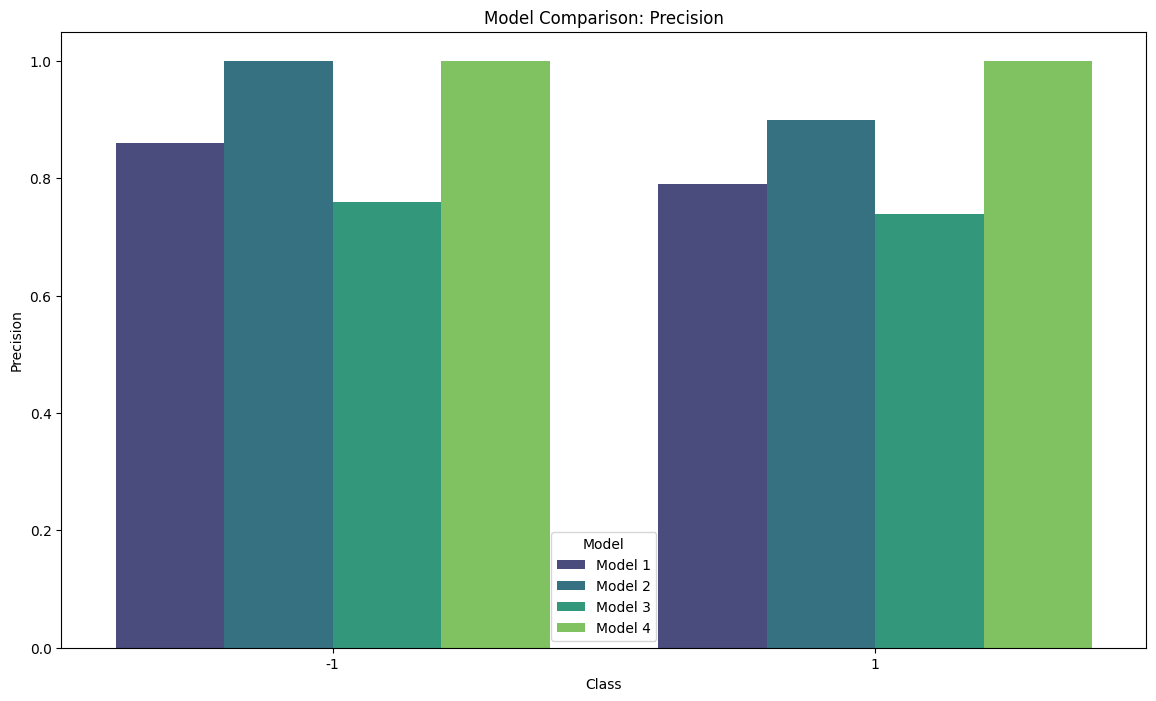

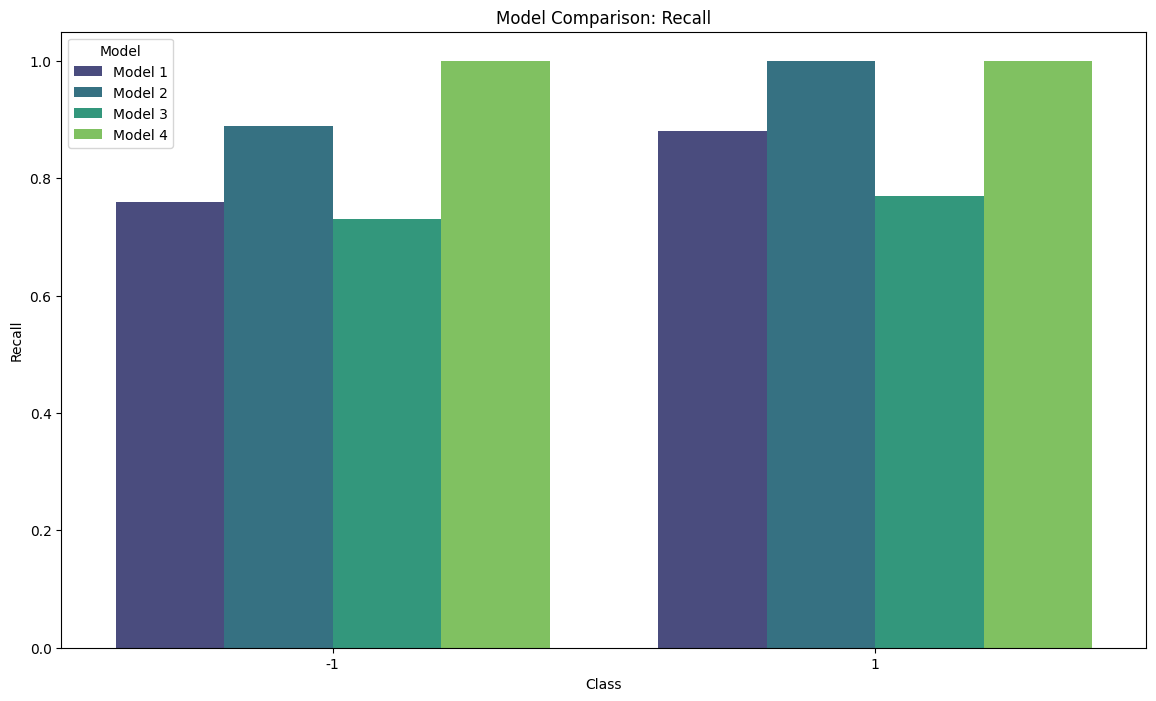

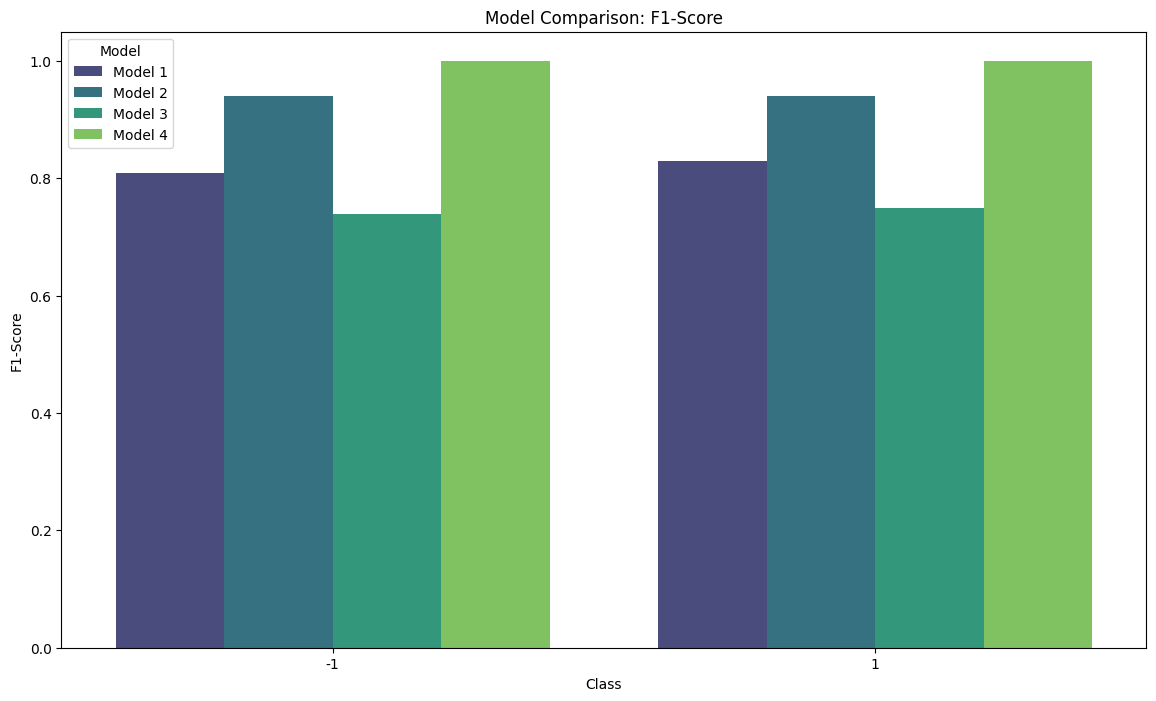

In [54]:
import re
import seaborn as sns 
print(report_svm)

def parse_classification_report(report):
    # Split the report into lines
    lines = report.split('\n')
    # Extract the metrics
    rows = []
    for line in lines[2:-5]:
        if line.strip():
            row = re.split(r'\s+', line.strip())
            rows.append(row)
    # Create a DataFrame
    df = pd.DataFrame(rows, columns=['Class', 'Precision', 'Recall', 'F1-score', 'Support'])
    # Convert columns to numeric
    df[['Precision', 'Recall', 'F1-score', 'Support']] = df[['Precision', 'Recall', 'F1-score', 'Support']].apply(pd.to_numeric)
    return df
report_df1 = parse_classification_report(report_svm)
report_df2 = parse_classification_report(report_knn)
report_df3 = parse_classification_report(report_lr)
report_df4 = parse_classification_report(report_tree)

# Add a model identifier
report_df1['Model'] = 'Model 1'
report_df2['Model'] = 'Model 2'
report_df3['Model'] = 'Model 3'
report_df4['Model'] = 'Model 4'

# Combine all DataFrames
combined_df = pd.concat([report_df1, report_df2, report_df3, report_df4])
combined_df.reset_index(drop=True, inplace=True)
# Plot precision
plt.figure(figsize=(14, 8))
sns.barplot(x='Class', y='Precision', hue='Model', data=combined_df, palette='viridis')
plt.title('Model Comparison: Precision')
plt.xlabel('Class')
plt.ylabel('Precision')
plt.show()

# Plot recall
plt.figure(figsize=(14, 8))
sns.barplot(x='Class', y='Recall', hue='Model', data=combined_df, palette='viridis')
plt.title('Model Comparison: Recall')
plt.xlabel('Class')
plt.ylabel('Recall')
plt.show()

# Plot F1-score
plt.figure(figsize=(14, 8))
sns.barplot(x='Class', y='F1-score', hue='Model', data=combined_df, palette='viridis')
plt.title('Model Comparison: F1-Score')
plt.xlabel('Class')
plt.ylabel('F1-Score')
plt.show()


## Test your Model and Report results

choose the best model from last section based on the evalutiona metrics and bar plots and after that train the best classifier based on train data and test it's performance on test data. With this, we can see how good the model is on unseen data.

- print `classification report` and plot `confusion matrix` based on your model's predictions and the real labels.

In [ ]:
# import necessary Libraries

In [61]:
# train the best model again and evaluate it on test data
knn_best = KNeighborsClassifier(algorithm= 'auto', metric = 'manhattan', n_neighbors = 9)

knn_best.fit(X_train_P, Y_train_C)
y_pred_best = knn_best.predict(X_test_P)


In [62]:
# classification report
print(classification_report(Y_test_C , y_pred_best))

              precision    recall  f1-score   support

          -1       0.89      0.96      0.92      2084
           1       0.62      0.37      0.46       382

    accuracy                           0.87      2466
   macro avg       0.75      0.66      0.69      2466
weighted avg       0.85      0.87      0.85      2466



In [58]:
# confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt


# Compute confusion matrix for test set
test_conf_matrix = confusion_matrix(Y_test_C, y_pred_best)

print("\nConfusion Matrix - Test Set:")
print(test_conf_matrix)



Confusion Matrix - Test Set:
[[1874  210]
 [ 230  152]]


## Clustering

When analyzing customer behavior, clustering algorithms can help identify groups of customers with similar characteristics. Two popular clustering methods are K-means and DBSCAN.  

In [59]:
#Kmeans (Use a method for finding optimal number of clusters)
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2)
kmeans.fit(X_S)
y_kmeans = kmeans.predict(X_S)
print(classification_report(Y , y_kmeans))


C:\Users\Arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


              precision    recall  f1-score   support

       False       0.83      0.89      0.86     10422
        True       0.01      0.00      0.00      1908

    accuracy                           0.76     12330
   macro avg       0.42      0.45      0.43     12330
weighted avg       0.70      0.76      0.73     12330



In [60]:
#DBSCAN
# Apply DBSCAN clustering
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=300, min_samples= 30 )
y_dbscan = dbscan.fit_predict(X_S)
print(classification_report(Y , y_dbscan))

              precision    recall  f1-score   support

       False       0.85      1.00      0.92     10422
        True       0.00      0.00      0.00      1908

    accuracy                           0.85     12330
   macro avg       0.42      0.50      0.46     12330
weighted avg       0.71      0.85      0.77     12330



C:\Users\Arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1469